In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

In [3]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("../data/raw")

train = pd.read_csv(DATA_DIR / "train.csv", low_memory=False)
store = pd.read_csv(DATA_DIR / "store.csv")

In [4]:
import pandas as pd
import numpy as np

df = train.copy()
df["Date"] = pd.to_datetime(df["Date"])

# For our initial conditional-on-open experiment
df = df[df["Open"] == 1].copy()

df = df.sort_values(["Date", "Store"]).reset_index(drop=True)

# Hold out the final 42 dates
dates = np.sort(df["Date"].unique())
split_date = dates[-42]

train_ml = df[df["Date"] < split_date].copy()
valid_ml = df[df["Date"] >= split_date].copy()

print("Split date:", split_date)
print("Training rows:", len(train_ml))
print("Validation rows:", len(valid_ml))
print("Training period:", train_ml["Date"].min(), "to", train_ml["Date"].max())
print("Validation period:", valid_ml["Date"].min(), "to", valid_ml["Date"].max())

Split date: 2015-06-20T00:00:00.000000000
Training rows: 804110
Validation rows: 40282
Training period: 2013-01-01 00:00:00 to 2015-06-19 00:00:00
Validation period: 2015-06-20 00:00:00 to 2015-07-31 00:00:00


In [5]:
store_mean = train_ml.groupby("Store")["Sales"].mean()

valid_a = valid_ml.copy()

valid_a["Prediction"] = valid_a["Store"].map(store_mean)

fallback = train_ml["Sales"].mean()

valid_a["Prediction"] = valid_a["Prediction"].fillna(fallback)

print(valid_a[["Date", "Store", "Sales", "Prediction"]].head())

             Date  Store  Sales   Prediction
804110 2015-06-20      1   4097  4776.826846
804111 2015-06-20      2   3020  4954.342246
804112 2015-06-20      3   3891  6947.705249
804113 2015-06-20      4   9374  9621.410428
804114 2015-06-20      5   2088  4685.900404


In [6]:
store_weekday_mean = (
    train_ml.groupby(["Store", "DayOfWeek"])["Sales"].mean()
)

valid_b = valid_ml.copy()

keys = pd.MultiIndex.from_frame(
    valid_b[["Store", "DayOfWeek"]]
)

valid_b["Prediction"] = store_weekday_mean.reindex(keys).to_numpy()

valid_b["Prediction"] = valid_b["Prediction"].fillna(
    valid_b["Store"].map(store_mean)
)

valid_b["Prediction"] = valid_b["Prediction"].fillna(fallback)

print(valid_b[["Date", "Store", "DayOfWeek", "Sales", "Prediction"]].head())

             Date  Store  DayOfWeek  Sales    Prediction
804110 2015-06-20      1          6   4097   4977.695312
804111 2015-06-20      2          6   3020   2863.210938
804112 2015-06-20      3          6   3891   4476.897638
804113 2015-06-20      4          6   9374  10136.406250
804114 2015-06-20      5          6   2088   2079.960938


In [7]:
def evaluate_forecast(actual, predicted):
    errors = actual.to_numpy() - predicted.to_numpy()

    mae = np.mean(np.abs(errors))
    rmse = np.sqrt(np.mean(errors ** 2))

    wape = (
        np.abs(errors).sum() / np.abs(actual.to_numpy()).sum()
    ) * 100

    bias = errors.mean()

    return {
        "MAE": mae,
        "RMSE": rmse,
        "WAPE (%)": wape,
        "Bias": bias
    }


results = pd.DataFrame({
    "Store Mean": evaluate_forecast(
        valid_a["Sales"], valid_a["Prediction"]
    ),
    "Store + Weekday Mean": evaluate_forecast(
        valid_b["Sales"], valid_b["Prediction"]
    )
}).T

display(results.round(2))

,MAE,RMSE,WAPE (%),Bias
Store Mean,1456.44,1934.37,20.87,40.99
Store + Weekday Mean,1254.18,1664.70,17.97,36.24


In [8]:
results.to_csv("../reports/baseline_results.csv")

print("Baseline results saved successfully!")

Baseline results saved successfully!


In [9]:
display(results.round(2))

,MAE,RMSE,WAPE (%),Bias
Store Mean,1456.44,1934.37,20.87,40.99
Store + Weekday Mean,1254.18,1664.70,17.97,36.24


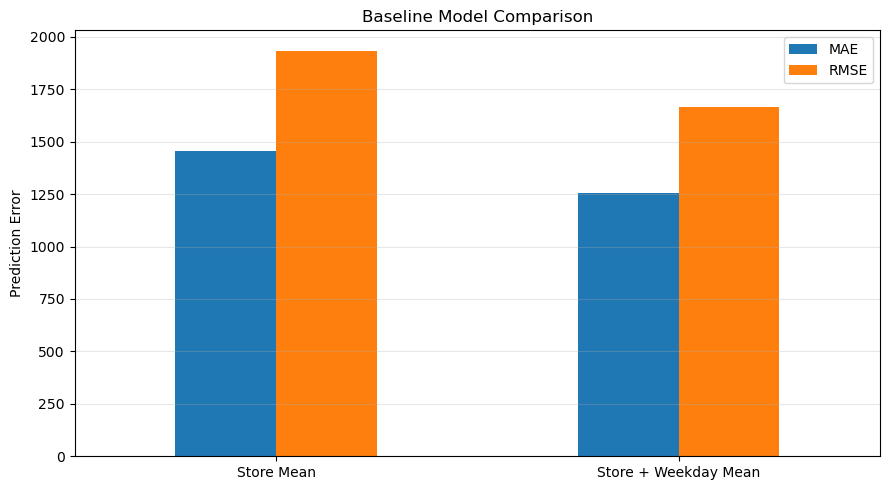

In [10]:
results[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Baseline Model Comparison")
plt.ylabel("Prediction Error")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

#Seven-Day Backtesting


In [13]:

# Prepare the data for rolling-origin backtesting

backtest_df = train.copy()
backtest_df["Date"] = pd.to_datetime(backtest_df["Date"])

# Initially forecast sales conditional on stores being open
backtest_df = backtest_df[backtest_df["Open"] == 1].copy()

backtest_df = backtest_df.sort_values(
    ["Date", "Store"]
).reset_index(drop=True)

# First forecast starts immediately after the training period
first_origin = split_date - pd.Timedelta(days=1)
last_date = valid_ml["Date"].max()

origins = pd.date_range(
    start=first_origin,
    end=last_date,
    freq="7D"
)

print("Number of forecast origins:", len(origins))
print("First forecast origin:", origins[0])
print("First forecast ends:", origins[0] + pd.Timedelta(days=7))


Number of forecast origins: 7
First forecast origin: 2015-06-19 00:00:00
First forecast ends: 2015-06-26 00:00:00


In [17]:

all_predictions = []

for origin in origins:

    # Historical data available at this forecast origin
    history = backtest_df[
        backtest_df["Date"] <= origin
    ].copy()

    # The next seven calendar days
    future = backtest_df[
        (backtest_df["Date"] > origin) &
        (backtest_df["Date"] <= origin + pd.Timedelta(days=7))
    ].copy()

    # Seasonal naive: use sales from seven days earlier
    previous_week = history[["Store", "Date", "Sales"]].copy()

    previous_week["Date"] = (
        previous_week["Date"] + pd.Timedelta(days=7)
    )

    previous_week = previous_week.rename(
        columns={"Sales": "Prediction"}
    )

    future = future.merge(
        previous_week,
        on=["Store", "Date"],
        how="left",
        validate="one_to_one"
    )

    # Historical store-weekday averages for fallback predictions
    weekday_mean = history.groupby(
        ["Store", "DayOfWeek"]
    )["Sales"].mean()

    keys = pd.MultiIndex.from_frame(
        future[["Store", "DayOfWeek"]]
    )

    fallback_predictions = weekday_mean.reindex(keys).to_numpy()

    future["Prediction"] = future["Prediction"].fillna(
        pd.Series(fallback_predictions, index=future.index)
    )

    # Final fallback for any remaining missing predictions
    future["Prediction"] = future["Prediction"].fillna(
        history["Sales"].mean()
    )

    future["ForecastOrigin"] = origin

    all_predictions.append(
        future[[
            "ForecastOrigin", "Date", "Store",
            "Sales", "Prediction"
        ]]
    )

backtest_results = pd.concat(
    all_predictions,
    ignore_index=True
)

display(backtest_results.head(10))


,ForecastOrigin,Date,Store,Sales,Prediction
0,2015-06-19,2015-06-20,1,4097,4256.0
1,2015-06-19,2015-06-20,2,3020,2574.0
2,2015-06-19,2015-06-20,3,3891,4687.0
3,2015-06-19,2015-06-20,4,9374,9779.0
4,2015-06-19,2015-06-20,5,2088,2156.0
5,2015-06-19,2015-06-20,6,2793,2812.0
6,2015-06-19,2015-06-20,7,5572,6590.0
7,2015-06-19,2015-06-20,8,3611,3456.0
8,2015-06-19,2015-06-20,9,6179,6165.0
9,2015-06-19,2015-06-20,10,4736,5892.0


In [18]:

seasonal_metrics = evaluate_forecast(
    backtest_results["Sales"],
    backtest_results["Prediction"]
)

display(
    pd.DataFrame(
        [seasonal_metrics],
        index=["Seasonal Naive"]
    ).round(2)
)

print("Forecast origins:", len(origins))
print("Forecast rows:", len(backtest_results))
print(
    "Forecast date range:",
    backtest_results["Date"].min(),
    "to",
    backtest_results["Date"].max()
)


,MAE,RMSE,WAPE (%),Bias
Seasonal Naive,2189.57,2821.6,31.38,7.68


Forecast origins: 6
Forecast rows: 40282
Forecast date range: 2015-06-20 00:00:00 to 2015-07-31 00:00:00


In [16]:
first_origin = split_date - pd.Timedelta(days=1)
last_origin = valid_ml["Date"].max() - pd.Timedelta(days=7)

origins = pd.date_range(
    start=first_origin,
    end=last_origin,
    freq="7D"
)

print("Number of origins:", len(origins))
print(origins)

Number of origins: 6
DatetimeIndex(['2015-06-19', '2015-06-26', '2015-07-03', '2015-07-10',
               '2015-07-17', '2015-07-24'],
              dtype='datetime64[ns]', freq='7D')


In [19]:
baseline_predictions = []

for origin in origins:

    history = backtest_df[
        backtest_df["Date"] <= origin
    ].copy()

    future = backtest_df[
        (backtest_df["Date"] > origin) &
        (backtest_df["Date"] <= origin + pd.Timedelta(days=7))
    ].copy()

    store_mean = history.groupby("Store")["Sales"].mean()
    store_weekday_mean = history.groupby(
        ["Store", "DayOfWeek"]
    )["Sales"].mean()

    fallback = history["Sales"].mean()

    future["StoreMeanPrediction"] = (
        future["Store"].map(store_mean).fillna(fallback)
    )

    keys = pd.MultiIndex.from_frame(
        future[["Store", "DayOfWeek"]]
    )

    weekday_predictions = store_weekday_mean.reindex(
        keys
    ).to_numpy()

    future["StoreWeekdayPrediction"] = pd.Series(
        weekday_predictions,
        index=future.index
    ).fillna(
        future["Store"].map(store_mean)
    ).fillna(fallback)

    future["ForecastOrigin"] = origin

    baseline_predictions.append(
        future[
            [
                "ForecastOrigin",
                "Date",
                "Store",
                "Sales",
                "StoreMeanPrediction",
                "StoreWeekdayPrediction"
            ]
        ]
    )

baseline_backtest = pd.concat(
    baseline_predictions,
    ignore_index=True
)

print("Rows:", len(baseline_backtest))
print("Origins:", baseline_backtest["ForecastOrigin"].nunique())

Rows: 40282
Origins: 6


In [20]:
store_mean_metrics = evaluate_forecast(
    baseline_backtest["Sales"],
    baseline_backtest["StoreMeanPrediction"]
)

store_weekday_metrics = evaluate_forecast(
    baseline_backtest["Sales"],
    baseline_backtest["StoreWeekdayPrediction"]
)

seasonal_metrics = evaluate_forecast(
    backtest_results["Sales"],
    backtest_results["Prediction"]
)

comparison = pd.DataFrame(
    [
        store_mean_metrics,
        store_weekday_metrics,
        seasonal_metrics
    ],
    index=[
        "Store Mean",
        "Store + Weekday Mean",
        "Seasonal Naive"
    ]
)

display(comparison.round(2))

,MAE,RMSE,WAPE (%),Bias
Store Mean,1456.18,1933.64,20.87,43.92
Store + Weekday Mean,1254.23,1664.50,17.97,39.33
Seasonal Naive,2189.57,2821.60,31.38,7.68


In [21]:
comparison.to_csv(
    "../reports/baseline_backtest_results.csv"
)

print("Baseline comparison saved successfully.")

Baseline comparison saved successfully.
